# 延迟运算

In [1]:
import polars as pl
import numpy as np
import threading
from helper.jupyter import row

Polars 的延迟运算不立即执行查询，而是先按「执行计划」累积，优化后一次性执行。主要好处如下。

- **自动优化**：省略多余的计算、调整操作顺序
- **内存效率**：只在需要的时点才处理
- **应对大规模数据**：降低内存不足的风险

## 基本流程  

1. 用 `DataFrame.lazy()` 转成 `LazyFrame`，或用 `scan_*()` 直接从文件取得 `LazyFrame`。  
2. 搭出过滤、聚合等处理链。  
3. 用 `collect()` 执行，或用 `explain()`、`show_graph()` 查看执行计划。  

下面的例子先用 `df.lazy()` 转成 `LazyFrame`，再用和 `DataFrame` 相同的方法搭处理链。  

In [2]:
df = pl.DataFrame({
    "product": ["A", "B", "C", "A", "B"],
    "category": ["X", "Y", "X", "Y", "X"],
    "price": [100, 200, 150, 300, 250],
    "quantity": [5, 3, 4, 2, 6]
})

lazy_operations = (
    df.lazy()
    .filter(pl.col("price") > 150)
    .filter(pl.col("price") < 280)
    .group_by("category")
    .agg(pl.col("quantity").sum().alias("total_quantity"))
)

用 `show_graph()` 可以分析执行计划。`optimized` 参数给 `True` 时看到的是优化后的计划。如下面的输出所示，优化后两个 `FILTER` 合并成了一个 `SELECTION`。  

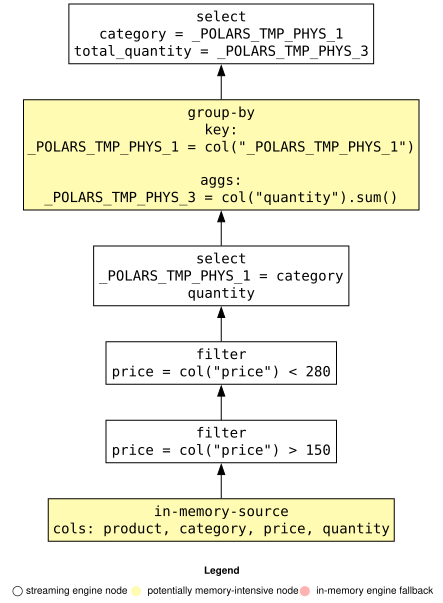

In [3]:
lazy_operations.show_graph(optimized=False)

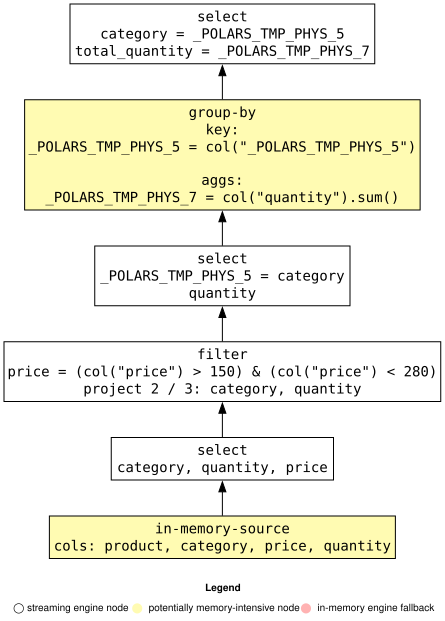

In [4]:
lazy_operations.show_graph(optimized=True)

取运算结果用 `collect()`。  

In [5]:
lazy_operations.collect()

category,total_quantity
str,i64
"""X""",6
"""Y""",3


`collect()` 执行后处理链仍然保留，所以可以再加 `sort()` 重新执行。  

In [6]:
lazy_operations.sort("total_quantity", descending=True).collect()

category,total_quantity
str,i64
"""X""",6
"""Y""",3


下表整理延迟运算与即时执行的差别。

| 特征                | 延迟运算 (Lazy)       | 即时执行 (Eager)       |
|---------------------|-----------------------|------------------------|
| 执行时机            | `collect()` 时一次性执行 | 每个操作立即执行     |
| 优化                | 自动进行              | 无                     |
| 内存效率            | 高                    | 低（保留中间结果）     |
| 主要用途            | 大规模数据、复杂处理  | 小规模数据、简单处理   |


## 流式处理


Polars 的流式处理（streaming）用来高效处理大规模数据集：把数据切成称为「chunk」（数据块）的小块，逐块处理。这样既压住内存占用，又能保持处理速度。

In [7]:
n = 1000
df = pl.LazyFrame({
    "A": np.random.randn(n),
    "B": np.random.randn(n),
    "C": np.random.randint(0, 10, n)
})

要确认某个运算能否流式处理，用 `.show_graph(engine="streaming", plan_stage="physical")`。
图里 **白色节点表示可以流式处理的运算**，**黄色节点表示能流式处理但可能占用较多内存的运算**。

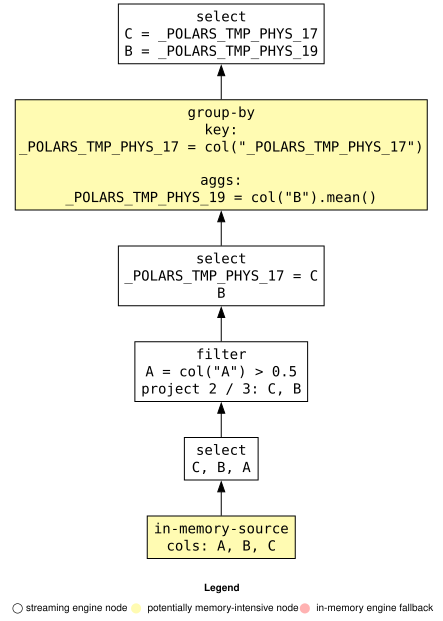

In [8]:
df2 = df.filter(pl.col('A') > 0.5).group_by('C').agg(pl.col('B').mean())
df2.show_graph(engine="streaming", plan_stage="physical")

给 `group_by()` 设了 `maintain_order=True` 时，`group_by()` 运算节点会显示成红色，无法流式处理。此时由 `"in-memory"` 引擎执行。

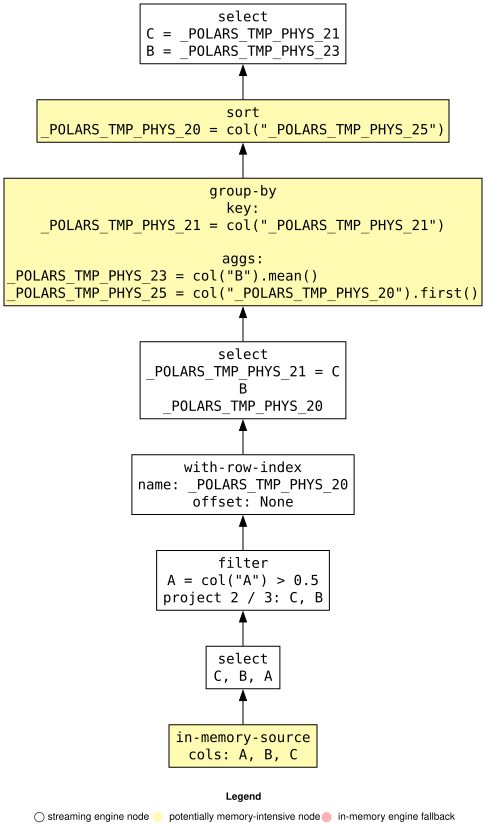

In [9]:
df3 = df.filter(pl.col('A') > 0.5).group_by('C', maintain_order=True).agg(pl.col('B').mean())
df3.show_graph(engine="streaming", plan_stage="physical")

要用流式处理算结果，调 `.collect(engine="streaming")`。能流式处理的部分会走流式，从而高效地算出结果。

In [10]:
row(df2.collect(engine="streaming"), df3.collect(engine="streaming"))

C,B
i32,f64
3,0.146326
1,-0.078783
4,-0.053964
0,0.284364
5,0.33791
7,-0.043352
9,0.056365
6,-0.143938
2,-0.040783


## 用 UDF 观察流式处理

要观察流式处理的行为，可以用 `map_batches()`、`map_element()` 这类用户定义函数（UDF：User-Defined Function）。在函数里打印数据长度和处理所在的线程，就能直接看到流式处理怎样切块、怎样并行。

### `Expr.map_batches`

下面的代码做了两件事：

* 用 `threading.Lock()` 防止多个线程的输出混在一起。
* 把 `map_batches()` 的 `is_elementwise` 参数设为 `True`，启用切块与并行。

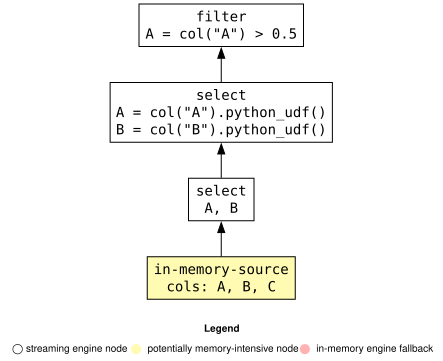

In [11]:
lock = threading.Lock()
def f(s):
    with lock:
        print(s.name, s.shape, threading.current_thread())
        return s

df4 = (
    df
    .select(
        pl.col('A', 'B').map_batches(f, return_dtype=pl.self_dtype(), is_elementwise=True)
    )
    .filter(pl.col('A') > 0.5)
)
df4.show_graph(engine="streaming", plan_stage="physical")

执行 `collect(engine="streaming")` 后，从输出可以看到 A 列和 B 列各被切成长度 125 的 chunk，在不同线程里并行处理。

In [12]:
df4.collect(engine="streaming");

A (50,) <_DummyThread(Dummy-13, started daemon 32024)>
A (50,) <_DummyThread(Dummy-14, started daemon 9668)>
A (50,) <_DummyThread(Dummy-15, started daemon 5916)>
A (50,) <_DummyThread(Dummy-16, started daemon 14852)>
A (50,) <_DummyThread(Dummy-17, started daemon 13196)>
A (50,) <_DummyThread(Dummy-18, started daemon 32592)>
A (50,) <_DummyThread(Dummy-19, started daemon 38080)>
A (50,) <_DummyThread(Dummy-20, started daemon 13172)>
A (50,) <_DummyThread(Dummy-21, started daemon 1912)>
A (50,) <_DummyThread(Dummy-22, started daemon 30804)>
A (50,) <_DummyThread(Dummy-23, started daemon 18848)>
A (50,) <_DummyThread(Dummy-24, started daemon 35424)>
A (50,) <_DummyThread(Dummy-25, started daemon 17944)>
A (50,) <_DummyThread(Dummy-26, started daemon 35668)>
A (50,) <_DummyThread(Dummy-27, started daemon 35188)>
A (50,) <_DummyThread(Dummy-28, started daemon 19680)>
A (50,) <_DummyThread(Dummy-29, started daemon 4812)>
A (50,) <_DummyThread(Dummy-30, started daemon 30016)>
A (50,) <_Dumm

而用 `in-memory` 引擎时，A 列和 B 列不会被切块，各自整体在单独的线程里处理。

In [13]:
df4.collect(engine="in-memory");

A (1000,) <_DummyThread(Dummy-53, started daemon 33672)>
B (1000,) <_DummyThread(Dummy-54, started daemon 26520)>


用 `scan_*()` 从文件读数据再处理时，事先不知道数据长度，所以如下面代码的输出所示，chunk 分不匀。

In [14]:
df.collect().write_csv('data/streaming_test.csv')
df5 = (
    pl
    .scan_csv('data/streaming_test.csv')
    .select(
        pl.col('A', 'B').map_batches(f, return_dtype=pl.self_dtype(), is_elementwise=True)
    )
    .filter(pl.col('A') > 0.5)
)
df5.collect(engine="streaming");

A (1000,) <_DummyThread(Dummy-55, started daemon 9668)>
B (1000,) <_DummyThread(Dummy-56, started daemon 32024)>


### `LazyFrame.map_batches`

`LazyFrame` 的 `map_batches()` 也支持流式处理。把 `streamable` 参数设为 `True` 即可。这时原始数据会被切成 chunk，每块作为 `DataFrame` 对象传给 UDF。

In [15]:
lock = threading.Lock()
def f(df):
    with lock:
        print(type(df).__name__, df.shape, threading.current_thread())
        return df

df2 = df.map_batches(f, streamable=True)
df2.collect(engine="streaming");

DataFrame (50, 3) <_DummyThread(Dummy-57, started daemon 36092)>
DataFrame (50, 3) <_DummyThread(Dummy-58, started daemon 25808)>
DataFrame (50, 3) <_DummyThread(Dummy-59, started daemon 4008)>
DataFrame (50, 3) <_DummyThread(Dummy-60, started daemon 15992)>
DataFrame (50, 3) <_DummyThread(Dummy-61, started daemon 4284)>
DataFrame (50, 3) <_DummyThread(Dummy-62, started daemon 4372)>
DataFrame (50, 3) <_DummyThread(Dummy-63, started daemon 32704)>
DataFrame (50, 3) <_DummyThread(Dummy-64, started daemon 37884)>
DataFrame (50, 3) <_DummyThread(Dummy-65, started daemon 10392)>
DataFrame (50, 3) <_DummyThread(Dummy-66, started daemon 32772)>
DataFrame (50, 3) <_DummyThread(Dummy-67, started daemon 15264)>
DataFrame (50, 3) <_DummyThread(Dummy-68, started daemon 32056)>
DataFrame (50, 3) <_DummyThread(Dummy-69, started daemon 36428)>
DataFrame (50, 3) <_DummyThread(Dummy-70, started daemon 13512)>
DataFrame (50, 3) <_DummyThread(Dummy-71, started daemon 18132)>
DataFrame (50, 3) <_DummyThr

### `Expr.map_elements`

`map_elements()` 把逐个值交给 UDF，再收集结果。用流式引擎时，运算会在多个线程上并行执行。

In [16]:
lock = threading.Lock()
def f(val):
    with lock:
        print(val, threading.current_thread())
        return val

n = 10

df = pl.LazyFrame({
    "A": np.random.randn(n),
    "B": np.random.randn(n),
    "C": np.random.randint(0, 10, n)
})
        
df2 = df.select(
    pl.col('A', 'B').map_elements(f, return_dtype=pl.self_dtype())
)

In [17]:
df2.collect(engine="streaming");

0.4310740772189506 <_DummyThread(Dummy-77, started daemon 14852)>
-0.08780386303380806 <_DummyThread(Dummy-78, started daemon 32592)>
1.6066741999080443 <_DummyThread(Dummy-79, started daemon 25356)>
-2.425285469132065 <_DummyThread(Dummy-80, started daemon 38080)>
0.6520199199399394 <_DummyThread(Dummy-81, started daemon 19680)>
-0.40886972227398755 <_DummyThread(Dummy-82, started daemon 30804)>
1.7449662628534852 <_DummyThread(Dummy-83, started daemon 18848)>
-0.5833514679929059 <_DummyThread(Dummy-84, started daemon 13172)>
-1.7790793645663876 <_DummyThread(Dummy-85, started daemon 35424)>
-0.3363777255719237 <_DummyThread(Dummy-86, started daemon 17944)>
1.2218168052517924 <_DummyThread(Dummy-87, started daemon 35668)>
-0.9958718756491378 <_DummyThread(Dummy-88, started daemon 35188)>
-0.1883572125781091 <_DummyThread(Dummy-89, started daemon 1912)>
0.3657342664658876 <_DummyThread(Dummy-90, started daemon 4812)>
0.3657448476152657 <_DummyThread(Dummy-91, started daemon 30016)>
-0.

In [18]:
df2.collect(engine="in-memory");

0.4310740772189506 <_DummyThread(Dummy-97, started daemon 33672)>
-0.3844051943765978 <_DummyThread(Dummy-97, started daemon 33672)>
1.6066741999080443 <_DummyThread(Dummy-97, started daemon 33672)>
-0.08780386303380806 <_DummyThread(Dummy-97, started daemon 33672)>
-2.425285469132065 <_DummyThread(Dummy-97, started daemon 33672)>
-0.1883572125781091 <_DummyThread(Dummy-97, started daemon 33672)>
-0.5833514679929059 <_DummyThread(Dummy-97, started daemon 33672)>
-0.40886972227398755 <_DummyThread(Dummy-97, started daemon 33672)>
1.7449662628534852 <_DummyThread(Dummy-97, started daemon 33672)>
-1.7790793645663876 <_DummyThread(Dummy-97, started daemon 33672)>
-0.3363777255719237 <_DummyThread(Dummy-98, started daemon 26520)>
1.2107276985340725 <_DummyThread(Dummy-98, started daemon 26520)>
-0.9958718756491378 <_DummyThread(Dummy-98, started daemon 26520)>
1.2218168052517924 <_DummyThread(Dummy-98, started daemon 26520)>
0.6520199199399394 <_DummyThread(Dummy-98, started daemon 26520)>
